# Détecteur et Classifieur d'Objets Spatiaux & Débris
Detecteur de Déchets 

Ce notebook prépare le pipeline complet de données avec **Pandas** et **TensorFlow**.
Chaque image contient un **unique objet** (satellite ou débris). Le pipeline génère ainsi deux cibles pour chaque image :
- `class_output` : l'identifiant de la classe binaire (2 classes : "satellite" ou "debris")
- `bbox_output` : les 4 coordonnées normalisées `[ymin, xmin, ymax, xmax]`

In [11]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
import yaml

# Configuration globale
IMG_SIZE = 224  # Taille standard adaptée aux backbones CNN (ex: MobileNetV2, ResNet)
BATCH_SIZE = 16

DATA_YAML_PATH = 'data/data.yaml'
with open(DATA_YAML_PATH, 'r', encoding='utf-8') as yaml_file:
  dataset_config = yaml.safe_load(yaml_file)

ORIGINAL_CLASS_NAMES = dataset_config['names']

# Classification binaire : regroupement de tous les satellites vs débris
CLASS_NAMES = ['satellite', 'debris']
NUM_CLASSES = len(CLASS_NAMES)

print(f"TensorFlow version: {tf.__version__}")
print(f"Classes originales ({len(ORIGINAL_CLASS_NAMES)}) : {ORIGINAL_CLASS_NAMES}")
print(f"Nouvelles classes ({NUM_CLASSES}) : {CLASS_NAMES}")


TensorFlow version: 2.21.0
Classes originales (11) : ['cheops', 'debris', 'double_start', 'earth_observation_sat_1', 'lisa_pathfinder', 'proba_2', 'proba_3_csc', 'proba_3_ocs', 'smart_1', 'soho', 'xmm_newton']
Nouvelles classes (2) : ['satellite', 'debris']


## 1. Préparation des DataFrames Pandas

Nous lisons les annotations YOLO (`[class_id, x_center, y_center, width, height]`) et les convertissons directement en `[ymin, xmin, ymax, xmax]`.
Chaque image contenant un unique objet, nous n'avons plus besoin de padding `MAX_BOXES`.

Tous les types de satellites sont regroupés sous la classe unique `"satellite"`, tandis que la classe `"debris"` est conservée.
Pour l'entraînement, nous limitons le nombre d'images de satellites afin d'utiliser **50% d'images de chaque classe** (équilibrage 50/50 débris vs satellites).

In [12]:
def create_dataset_dataframe(image_dir):
    """
    Lit les images et leurs étiquettes YOLO pour créer un DataFrame Pandas tabulaire.
    Regroupe tous les satellites sous la classe 'satellite' et conserve 'debris'.
    """
    image_paths = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
    records = []

    for img_path in image_paths:
        label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                line = f.readline().strip()
                if line:
                    parts = line.split()
                    raw_cls_id = int(parts[0])
                    x_c, y_c, w, h = map(float, parts[1:5])

                    # Conversion YOLO (x_center, y_center, w, h) -> (ymin, xmin, ymax, xmax)
                    ymin = max(0.0, y_c - (h / 2.0))
                    xmin = max(0.0, x_c - (w / 2.0))
                    ymax = min(1.0, y_c + (h / 2.0))
                    xmax = min(1.0, x_c + (w / 2.0))

                    # Regroupement binaire : 'debris' vs 'satellite'
                    raw_name = ORIGINAL_CLASS_NAMES[raw_cls_id] if 0 <= raw_cls_id < len(ORIGINAL_CLASS_NAMES) else 'unknown'
                    new_name = 'debris' if raw_name == 'debris' else 'satellite'
                    cls_id = CLASS_NAMES.index(new_name)

                    records.append({
                        'image_path': img_path,
                        'class_id': cls_id,
                        'class_name': new_name,
                        'original_class_name': raw_name,
                        'ymin': ymin,
                        'xmin': xmin,
                        'ymax': ymax,
                        'xmax': xmax,
                    })

    return pd.DataFrame(records)

# Création des DataFrames initiaux
df_train_raw = create_dataset_dataframe('data/train/images')
df_val       = create_dataset_dataframe('data/valid/images')
df_test      = create_dataset_dataframe('data/test/images')

# Équilibrage à 50% de chaque classe pour l'entraînement (sous-échantillonnage des satellites)
n_debris_train = (df_train_raw['class_name'] == 'debris').sum()
df_train_debris = df_train_raw[df_train_raw['class_name'] == 'debris']
df_train_satellites = df_train_raw[df_train_raw['class_name'] == 'satellite'].sample(
    n=n_debris_train, random_state=42
)

# Concaténation et mélange du jeu d'entraînement
df_train = pd.concat([df_train_debris, df_train_satellites]).sample(
    frac=1.0, random_state=42
).reset_index(drop=True)

print(f"Train initial : {len(df_train_raw)} images (Débris: {n_debris_train}, Satellites: {(df_train_raw['class_name'] == 'satellite').sum()})")
print(f"Train équilibré (50% / 50%) : {len(df_train)} images (Débris: {(df_train['class_name'] == 'debris').sum()}, Satellites: {(df_train['class_name'] == 'satellite').sum()})")
print(f"Val   : {len(df_val)} images")
print(f"Test  : {len(df_test)} images")
df_train.head()


Train initial : 2105 images (Débris: 186, Satellites: 1919)
Train équilibré (50% / 50%) : 372 images (Débris: 186, Satellites: 186)
Val   : 239 images
Test  : 123 images


,image_path,class_id,class_name,original_class_name,ymin,xmin,ymax,xmax
0,data/train/images/img031295_jpg.rf.8c57bd59ddc...,0,satellite,double_start,0.458594,0.426562,0.752344,0.715625
1,data/train/images/img022231_jpg.rf.701c1eb8209...,1,debris,debris,0.261328,0.364062,0.458984,0.625000
2,data/train/images/img022080_jpg.rf.a66fe17e413...,1,debris,debris,0.462109,0.410547,0.647266,0.587891
3,data/train/images/img101277_jpg.rf.879a37ed752...,0,satellite,xmm_newton,0.198437,0.005078,0.876562,0.566797
4,data/train/images/img022454_jpg.rf.115bc86337a...,1,debris,debris,0.587500,0.182422,0.729687,0.305078


## 2. Exploration des données (EDA)
Vérifions la distribution des classes dans l'ensemble d'entraînement.


In [13]:
print("Distribution des classes (Train) :\n", df_train['class_name'].value_counts())
print("\nProportion des classes (Train) :\n", df_train['class_name'].value_counts(normalize=True) * 100)


Distribution des classes (Train) :
 class_name
satellite    186
debris       186
Name: count, dtype: int64

Proportion des classes (Train) :
 class_name
satellite    50.0
debris       50.0
Name: proportion, dtype: float64


## 3. Pipeline TensorFlow (`tf.data`)

Nous transformons directement les DataFrames Pandas en `tf.data.Dataset` optimisés via `tf.data.Dataset.from_tensor_slices` :
- Chargement et décodage multithreadés (`AUTOTUNE`)
- Redimensionnement à `IMG_SIZE` et normalisation dans `[0, 1]`
- Sortie au format dictionnaire `{'class_output': ..., 'bbox_output': ...}` prêt pour un modèle multi-tâches (classification + localisation)


In [14]:
def df_to_tf_dataset(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE, is_training=True):
    image_paths = df['image_path'].values
    bboxes = df[['ymin', 'xmin', 'ymax', 'xmax']].values.astype(np.float32)
    class_ids = df['class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, bboxes, class_ids))

    def load_and_preprocess(img_path, bbox, cls_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32) / 255.0
        return img, {
            'class_output': cls_id,
            'bbox_output': bbox,
        }

    if is_training:
        dataset = dataset.shuffle(buffer_size=min(len(df), 1000), reshuffle_each_iteration=True)

    dataset = dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds = df_to_tf_dataset(df_train, is_training=True)
val_ds   = df_to_tf_dataset(df_val, is_training=False)
test_ds  = df_to_tf_dataset(df_test, is_training=False)

print("Datasets TensorFlow construits et prêts pour l'entraînement !")


Datasets TensorFlow construits et prêts pour l'entraînement !


## 4. Visualisation d'un lot pour vérification
Affichons un lot d'entraînement avec l'étiquette de classe et la boîte englobante correspondante.


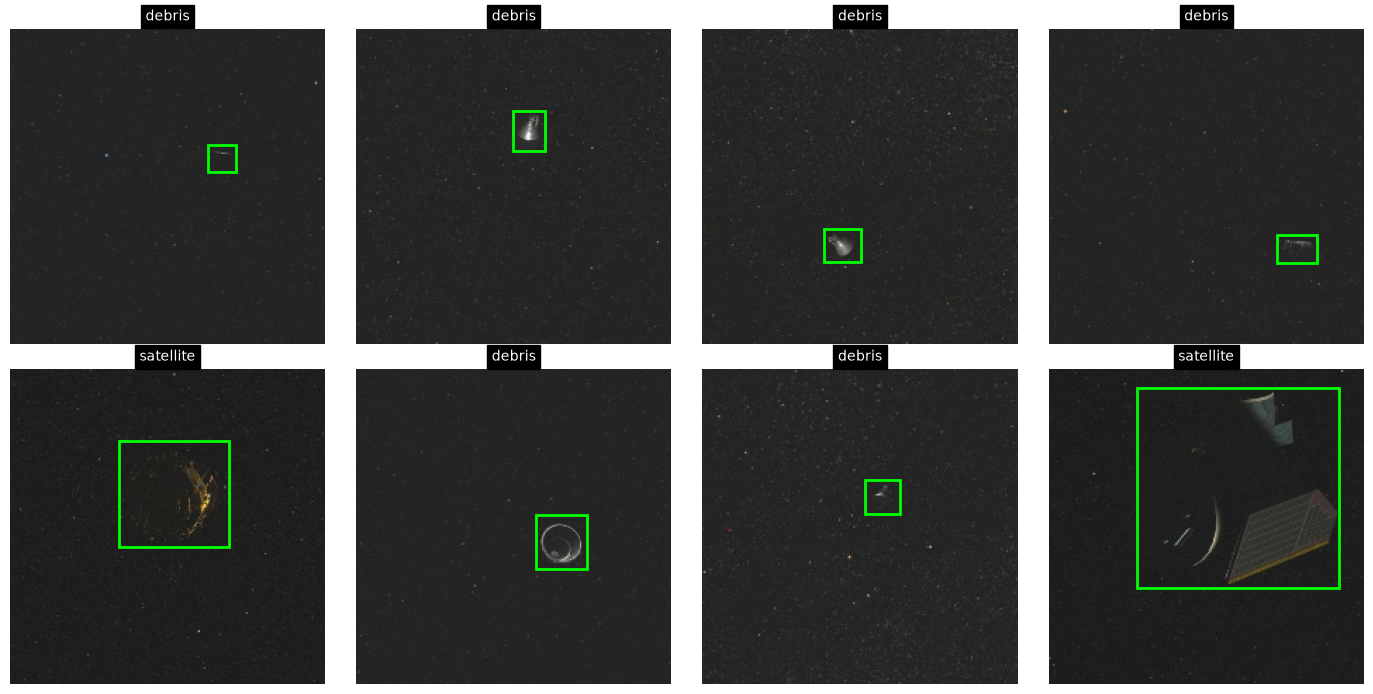

In [15]:
for images, targets in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i in range(min(8, len(images))):
        img = images[i].numpy()
        cls_id = int(targets['class_output'][i].numpy())
        ymin, xmin, ymax, xmax = targets['bbox_output'][i].numpy()

        h, w, _ = img.shape
        box_y = ymin * h
        box_x = xmin * w
        box_h = (ymax - ymin) * h
        box_w = (xmax - xmin) * w

        axes[i].imshow(img)
        rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='lime', facecolor='none')
        axes[i].add_patch(rect)
        axes[i].set_title(f"{CLASS_NAMES[cls_id]}", color='white', backgroundcolor='black', fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
    break


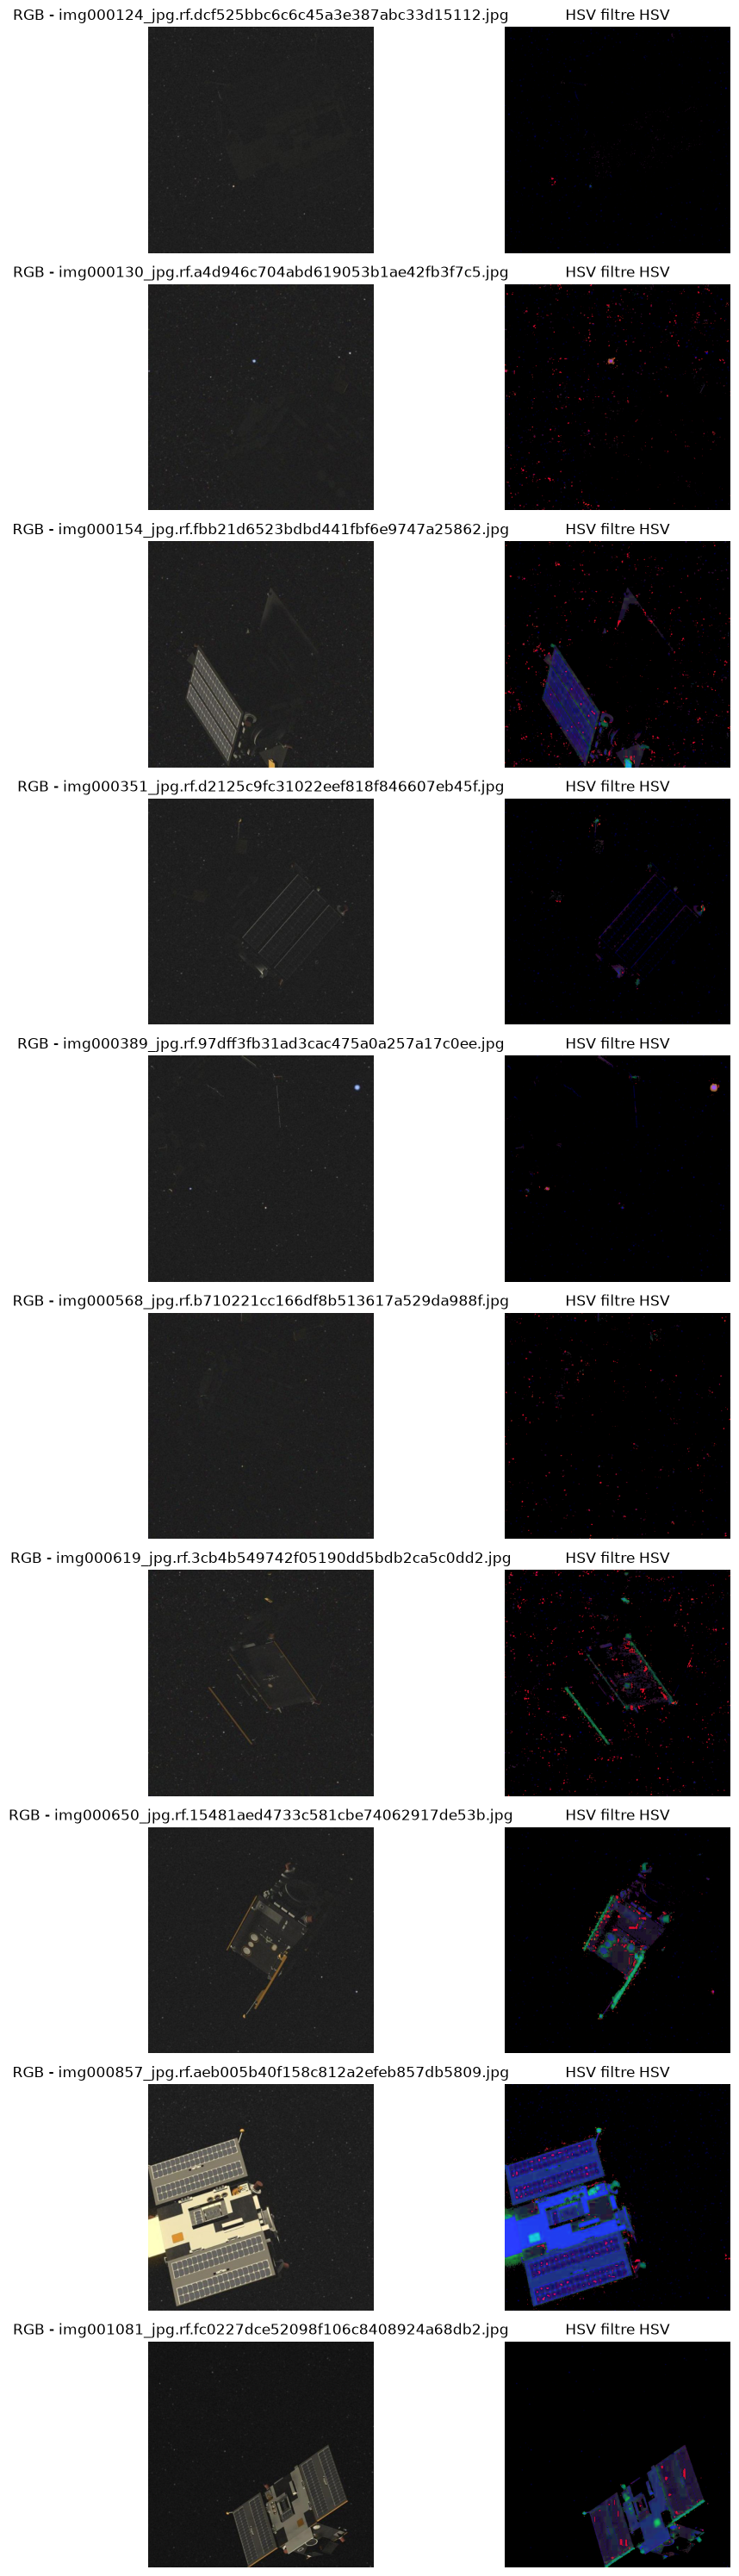

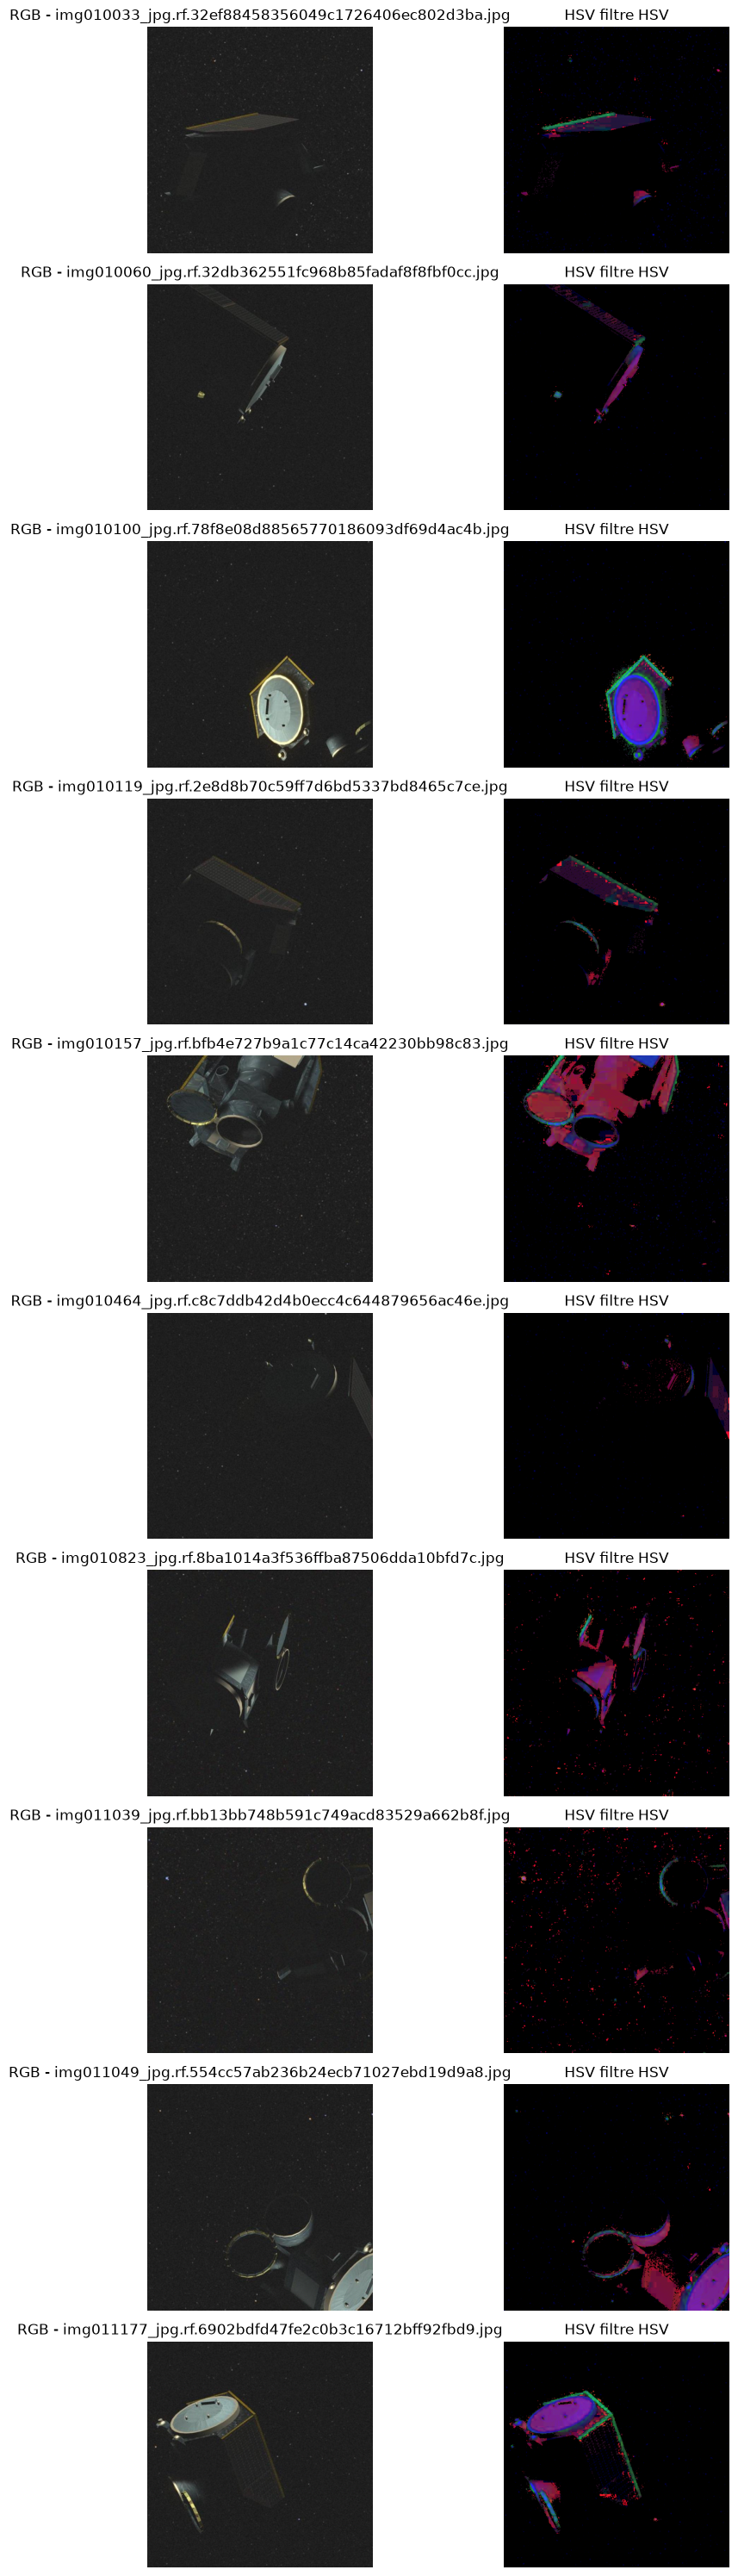

20 images filtrees avec le reglage HSV.


In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import rgb_to_hsv
from PIL import Image

images_dir = Path("data/test/images")
image_paths = sorted(
    path for path in images_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)[:20]

# Bornes reglables des trois composantes HSV : H (teinte), S (saturation), V (luminosite).
# Pour les modifier, conserver des valeurs comprises entre 0.0 et 1.0.
hue_range = (0.0, 1.0)
saturation_range = (0.0, 1.0)
value_range = (0.15, 1.0)

# Reinitialise les resultats pour ne pas reutiliser ceux d'une execution precedente.
hsv_images = []

# Traite chaque image individuellement.
for image_path in image_paths:
    # Charge l'image en RGB et normalise ses pixels entre 0 et 1.
    arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0

    # Convertit l'image RGB dans l'espace HSV.
    hsv = rgb_to_hsv(arr)

    # Construit un masque qui conserve uniquement les pixels dans les plages HSV choisies.
    mask = (
        (hsv[:, :, 0] >= hue_range[0]) & (hsv[:, :, 0] <= hue_range[1])
        & (hsv[:, :, 1] >= saturation_range[0]) & (hsv[:, :, 1] <= saturation_range[1])
        & (hsv[:, :, 2] >= value_range[0]) & (hsv[:, :, 2] <= value_range[1])
    )

    # Met a zero les pixels du fond qui ne respectent pas les plages HSV.
    hsv_filtered = hsv.copy()
    hsv_filtered[~mask] = 0.0
    hsv_images.append(hsv_filtered)

# Affiche les images par pages de 10.
images_per_page = 10
for page_start in range(0, len(image_paths), images_per_page):
    page_paths = image_paths[page_start:page_start + images_per_page]
    page_hsv = hsv_images[page_start:page_start + images_per_page]
    figure, axes = plt.subplots(len(page_paths), 2, figsize=(10, 3 * len(page_paths)))
    axes = np.atleast_2d(axes)

    # Affiche chaque paire RGB/HSV avec le nom du fichier.
    for row, (image_path, hsv) in enumerate(zip(page_paths, page_hsv)):
        arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0
        axes[row, 0].imshow(arr)
        axes[row, 0].set_title(f"RGB - {image_path.name}")
        axes[row, 1].imshow(hsv)
        axes[row, 1].set_title("HSV filtre HSV")
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    # Ajuste la mise en page, affiche la page et libere la figure.
    figure.tight_layout()
    plt.show()
    plt.close(figure)

print(f"{len(hsv_images)} images filtrees avec le reglage HSV.")

## 5. Modélisation : Architecture Multi-Tâches (Classification & Localisation)

Pour répondre aux deux objectifs simultanément (reconnaître la classe de l'objet et localiser sa position), nous concevons un réseau **multi-tâches** avec transfert d'apprentissage (*Transfer Learning*) basé sur **MobileNetV2** (pré-entraîné sur ImageNet) :
1. **Backbone d'extraction :** `MobileNetV2` (poids ImageNet gelés) pour extraire les caractéristiques visuelles riches tout en restant rapide à l'entraînement.
2. **Tête de classification binaire :** Prédit la probabilité des 2 classes (`satellite` ou `debris`) via `Dense(num_classes, activation="softmax")` optimisé par `sparse_categorical_crossentropy`.
3. **Tête de localisation (Bounding Box) :** Prédit directement les 4 coordonnées normalisées `[ymin, xmin, ymax, xmax]` via `Dense(4, activation="sigmoid")` avec une perte de type `Huber Loss` (robuste aux valeurs aberrantes).

In [17]:
from tensorflow.keras import layers, models

def build_multitask_model(num_classes=NUM_CLASSES, img_size=IMG_SIZE):
    """
    Construit un modèle multi-sorties avec Transfer Learning (MobileNetV2) :
    - 'class_output' : classification binaire (2 classes : 'satellite' ou 'debris')
    - 'bbox_output'  : régression des 4 coordonnées normalisées [ymin, xmin, ymax, xmax]
    """
    inputs = layers.Input(shape=(img_size, img_size, 3), name="input_image")
    
    # Backbone pré-entraîné
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False  # Gel des poids initiaux
    
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    
    # Tête 1 : Classification binaire
    c = layers.Dense(128, activation="relu", name="class_dense")(x)
    c = layers.Dropout(0.3, name="class_dropout")(c)
    class_output = layers.Dense(num_classes, activation="softmax", name="class_output")(c)
    
    # Tête 2 : Régression de la boîte englobante
    b = layers.Dense(64, activation="relu", name="bbox_dense")(x)
    b = layers.Dropout(0.2, name="bbox_dropout")(b)
    bbox_output = layers.Dense(4, activation="sigmoid", name="bbox_output")(b)
    
    model = models.Model(
        inputs=inputs,
        outputs={"class_output": class_output, "bbox_output": bbox_output},
        name="space_multitask_detector"
    )
    return model

# Création du modèle
model = build_multitask_model()
model.summary()

# Compilation multi-sorties
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss={
        "class_output": "sparse_categorical_crossentropy",
        "bbox_output": tf.keras.losses.Huber(delta=1.0)
    },
    loss_weights={
        "class_output": 1.0,
        "bbox_output": 5.0
    },
    metrics={
        "class_output": "accuracy",
        "bbox_output": "mae"
    }
)
print("Modèle multi-tâches compilé et prêt !")


Model: "space_multitask_detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ input_image[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_dense (Dense)  │ (None, 64)        │     81,984 │ global_avg_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_dense (Dense) │ (None, 128)       │    163,968 │ global_avg_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_dropout        │ (None, 64)        │          0 │ bbox_dense[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_dropout       │ (None, 128)       │          0 │ class_dense[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │        260 │ bbox_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 2)         │        258 │ class_dropout[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,504,454 (9.55 MB)

 Trainable params: 246,470 (962.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Modèle multi-tâches compilé et prêt !


## 6. Entraînement du Modèle avec Callbacks

Nous utilisons des rappels (*callbacks*) pour sécuriser l'entraînement :
- `EarlyStopping` : arrête l'entraînement si la perte de validation cesse de s'améliorer.
- `ReduceLROnPlateau` : réduit automatiquement le taux d'apprentissage lors des plateaux.
- `ModelCheckpoint` : sauvegarde le modèle optimal.


In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="best_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

EPOCHS = 10  # Ajustable selon le temps de calcul souhaité

# Lancement de l'entraînement
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/10


/home/thomas/Bureau/CPE/S9/IA Machine Learning/ia_deep_learning_projet/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - bbox_output_loss: 0.0238 - bbox_output_mae: 0.1759 - class_output_accuracy: 0.8091 - class_output_loss: 0.4078 - loss: 0.5365
Epoch 1: val_loss improved from None to 0.31688, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 768ms/step - bbox_output_loss: 0.0238 - bbox_output_mae: 0.1759 - class_output_accuracy: 0.8091 - class_output_loss: 0.4078 - loss: 0.5365 - val_bbox_output_loss: 0.0177 - val_bbox_output_mae: 0.1514 - val_class_output_accuracy: 0.8954 - val_class_output_loss: 0.2283 - val_loss: 0.3169 - learning_rate: 0.0010
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - bbox_output_loss: 0.0149 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9435 - class_output_loss: 0.2001 - loss: 0.2824
Epoch 2: val_loss did not improve from 0.31688
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 669ms/step - bbox_output_loss: 0.0149 - bbox_output_mae: 0.1435 - class_output_accuracy: 0.9435 -

## 7. Résultats de l'Entraînement et Évaluation sur le Jeu de Test

Nous traçons les courbes d'apprentissage (perte, précision de classification et MAE de la boîte) et évaluons les performances sur le jeu de test indépendant (`test_ds`).


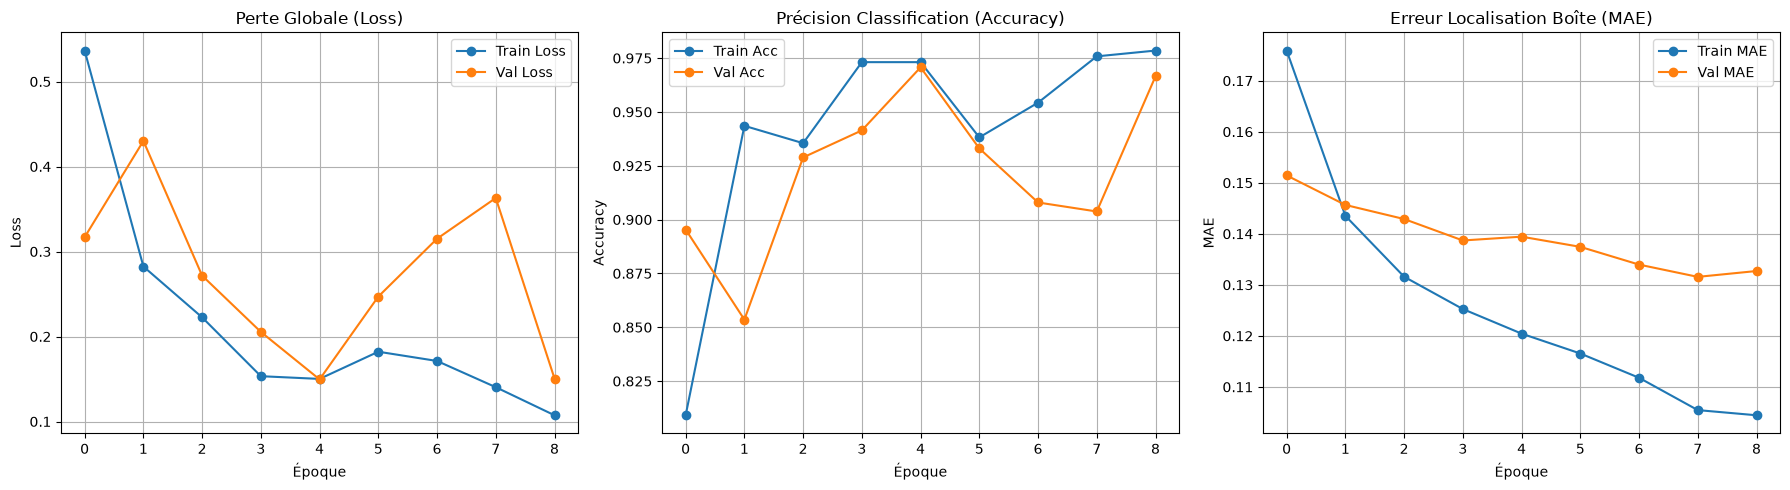

=== ÉVALUATION SUR LE JEU DE TEST (123 images) ===
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 381ms/step - bbox_output_loss: 0.0139 - bbox_output_mae: 0.1319 - class_output_accuracy: 0.9268 - class_output_loss: 0.1627 - loss: 0.2298
  bbox_output_loss          : 0.0139
  bbox_output_mae           : 0.1319
  class_output_accuracy     : 0.9268
  class_output_loss         : 0.1627
  loss                      : 0.2298


In [19]:
# 1. Courbes d'apprentissage (Loss, Accuracy, MAE)
if 'history' in globals():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Perte globale
    axes[0].plot(history.history['loss'], label='Train Loss', marker='o')
    axes[0].plot(history.history['val_loss'], label='Val Loss', marker='o')
    axes[0].set_title('Perte Globale (Loss)', fontsize=12)
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)
    
    # Précision classification
    axes[1].plot(history.history['class_output_accuracy'], label='Train Acc', marker='o')
    axes[1].plot(history.history['val_class_output_accuracy'], label='Val Acc', marker='o')
    axes[1].set_title('Précision Classification (Accuracy)', fontsize=12)
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True)
    
    # Erreur de localisation
    axes[2].plot(history.history['bbox_output_mae'], label='Train MAE', marker='o')
    axes[2].plot(history.history['val_bbox_output_mae'], label='Val MAE', marker='o')
    axes[2].set_title('Erreur Localisation Boîte (MAE)', fontsize=12)
    axes[2].set_xlabel('Époque')
    axes[2].set_ylabel('MAE')
    axes[2].legend()
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.show()

# 2. Évaluation chiffrée sur le jeu de test
print('=== ÉVALUATION SUR LE JEU DE TEST (123 images) ===')
# On charge le meilleur modèle sauvegardé
best_model = tf.keras.models.load_model('best_model.keras')
eval_results = best_model.evaluate(test_ds, return_dict=True)
for k, v in eval_results.items():
    print(f"  {k:<26}: {v:.4f}")


## 8. Visualisation des Prédictions sur le Jeu de Test

Comparaison visuelle entre la **vérité terrain** (boîte verte) et la **prédiction du modèle** (boîte rouge pointillée), avec la classe prédite et son niveau de confiance.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step


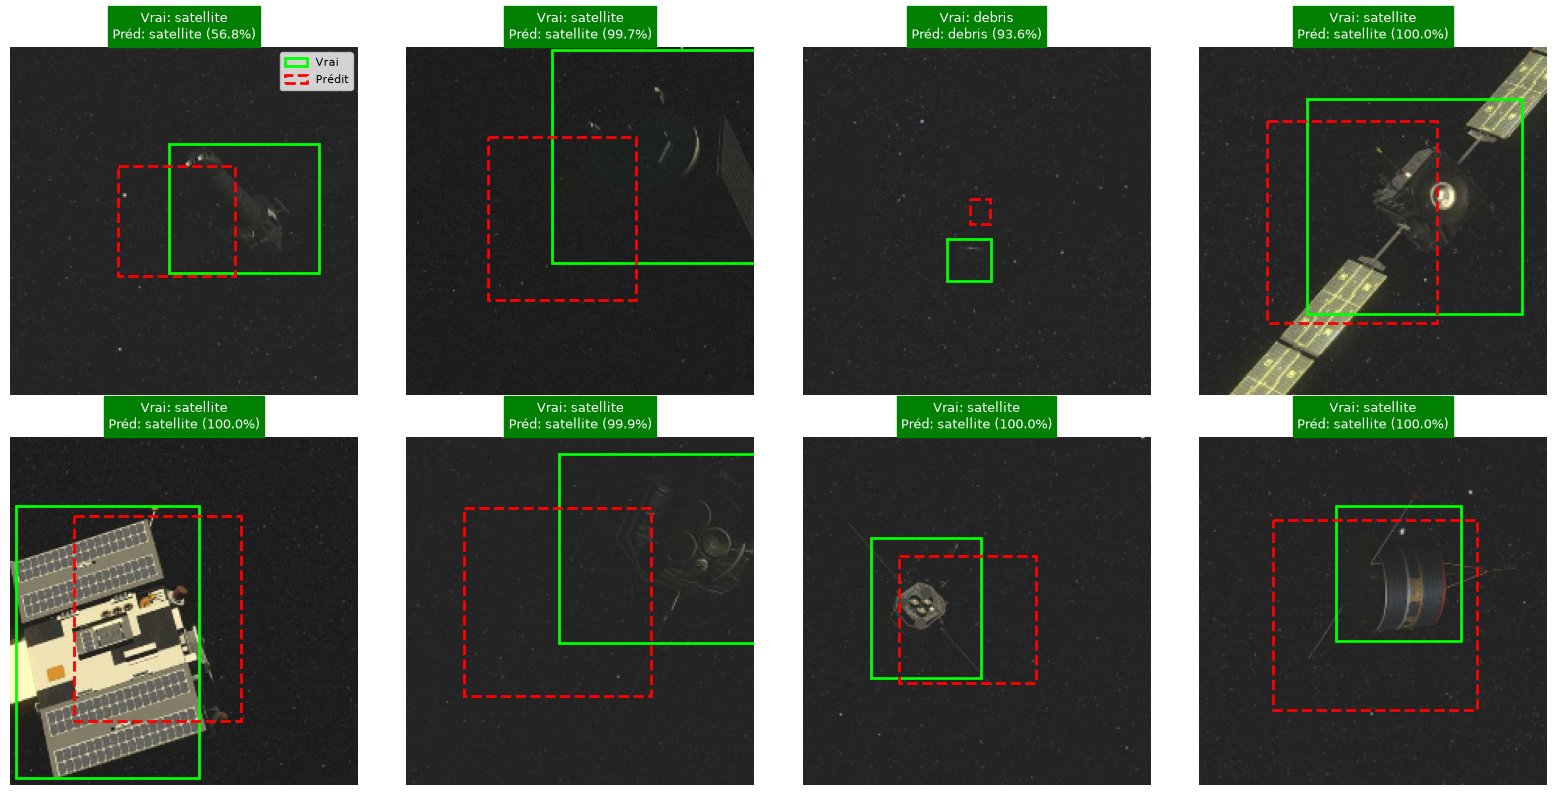

In [23]:
# Unbatch, mélange aléatoire sur tout le dataset, puis re-batch de 8 éléments
test_ds_random = test_ds.unbatch().shuffle(buffer_size=1000, reshuffle_each_iteration=True).batch(8)

for images, targets in test_ds_random.take(1):
    predictions = best_model.predict(images)
    pred_classes = np.argmax(predictions['class_output'], axis=1)
    pred_probs = np.max(predictions['class_output'], axis=1)
    pred_boxes = predictions['bbox_output']
    
    true_classes = targets['class_output'].numpy()
    true_boxes = targets['bbox_output'].numpy()
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    
    for i in range(min(8, len(images))):
        img = images[i].numpy()
        h, w, _ = img.shape
        
        # Boîte réelle (vert)
        ty_min, tx_min, ty_max, tx_max = true_boxes[i]
        tb_y, tb_x = ty_min * h, tx_min * w
        tb_h, tb_w = (ty_max - ty_min) * h, (tx_max - tx_min) * w
        
        # Boîte prédite (rouge)
        py_min, px_min, py_max, px_max = pred_boxes[i]
        pb_y, pb_x = py_min * h, px_min * w
        pb_h, pb_w = (py_max - py_min) * h, (px_max - px_min) * w
        
        axes[i].imshow(img)
        # Dessin vérité terrain
        rect_true = patches.Rectangle((tb_x, tb_y), tb_w, tb_h, linewidth=2, edgecolor='lime', facecolor='none', label='Vrai')
        axes[i].add_patch(rect_true)
        # Dessin prédiction
        rect_pred = patches.Rectangle((pb_x, pb_y), pb_w, pb_h, linewidth=2, edgecolor='red', linestyle='--', facecolor='none', label='Prédit')
        axes[i].add_patch(rect_pred)
        
        true_label = CLASS_NAMES[true_classes[i]]
        pred_label = CLASS_NAMES[pred_classes[i]]
        is_correct = (true_classes[i] == pred_classes[i])
        title_color = 'green' if is_correct else 'red'
        
        axes[i].set_title(
            f"Vrai: {true_label}\nPréd: {pred_label} ({pred_probs[i]*100:.1f}%)",
            color='white',
            backgroundcolor=title_color,
            fontsize=9
        )
        axes[i].axis('off')
        if i == 0:
            axes[i].legend(loc='upper right', fontsize=8)
            
    plt.tight_layout()
    plt.show()
    break